<p style="text-align:center">
    <a href="https://skills.network/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDS0321ENSkillsNetwork26802033-2022-01-01" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# **Space X  Falcon 9 First Stage Landing Prediction**


## Hands on Lab: Complete the Machine Learning Prediction lab


Estimated time needed: **60** minutes


Space X advertises Falcon 9 rocket launches on its website with a cost of 62 million dollars; other providers cost upward of 165 million dollars each, much of the savings is because Space X can reuse the first stage. Therefore if we can determine if the first stage will land, we can determine the cost of a launch. This information can be used if an alternate company wants to bid against space X for a rocket launch.   In this lab, you will create a machine learning pipeline  to predict if the first stage will land given the data from the preceding labs.


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/landing_1.gif)


Several examples of an unsuccessful landing are shown here:


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/crash.gif)


Most unsuccessful landings are planed. Space X; performs a controlled landing in the oceans.


## Objectives


Perform exploratory  Data Analysis and determine Training Labels

*   create a column for the class
*   Standardize the data
*   Split into training data and test data

\-Find best Hyperparameter for SVM, Classification Trees and Logistic Regression

*   Find the method performs best using test data


## Import Libraries and Define Auxiliary Functions


In [ ]:
!pip install numpy
!pip install pandas
!pip install seaborn
!pip install scikit-learn

We will import the following libraries for the lab


In [ ]:
# Pandas is a software library written for the Python programming language for data manipulation and analysis.
import pandas as pd
# NumPy is a library for the Python programming language, adding support for large, multi-dimensional arrays and matrices, along with a large collection of high-level mathematical functions to operate on these arrays
import numpy as np
# Matplotlib is a plotting library for python and pyplot gives us a MatLab like plotting framework. We will use this in our plotter function to plot data.
import matplotlib.pyplot as plt
#Seaborn is a Python data visualization library based on matplotlib. It provides a high-level interface for drawing attractive and informative statistical graphics
import seaborn as sns
# Preprocessing allows us to standarsize our data
from sklearn import preprocessing
# Allows us to split our data into training and testing data
from sklearn.model_selection import train_test_split
# Allows us to test parameters of classification algorithms and find the best one
from sklearn.model_selection import GridSearchCV
# Logistic Regression classification algorithm
from sklearn.linear_model import LogisticRegression
# Support Vector Machine classification algorithm
from sklearn.svm import SVC
# Decision Tree classification algorithm
from sklearn.tree import DecisionTreeClassifier
# K Nearest Neighbors classification algorithm
from sklearn.neighbors import KNeighborsClassifier

In [1]:
import pandas as pd
import numpy as np

from sklearn import preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# ==========================================
# 1. LOAD DATASETS
# ==========================================

data = pd.read_csv(
    "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv"
)

X = pd.read_csv(
    "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_3.csv"
)

Y = data["Class"].to_numpy()

# ==========================================
# 2. STANDARDIZE FEATURES
# ==========================================

transform = preprocessing.StandardScaler()
X = transform.fit_transform(X)

# ==========================================
# 3. SPLIT DATA
# ==========================================

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=2
)

# ==========================================
# QUESTION 1: TEST SAMPLE SIZE
# ==========================================

print("QUESTION 1:", len(Y_test), "records")

# ==========================================
# 4. SUPPORT VECTOR MACHINE
# ==========================================

svm_parameters = {
    "kernel": ("linear", "rbf", "poly", "rbf", "sigmoid"),
    "C": np.logspace(-3, 3, 5),
    "gamma": np.logspace(-3, 3, 5)
}

svm = SVC()

svm_cv = GridSearchCV(
    svm,
    svm_parameters,
    cv=10
)

svm_cv.fit(X_train, Y_train)

# ==========================================
# QUESTION 2: BEST SVM KERNEL
# ==========================================

print("QUESTION 2:", svm_cv.best_params_["kernel"])

# ==========================================
# 5. DECISION TREE
# ==========================================

tree_parameters = {
    "criterion": ["gini", "entropy"],
    "splitter": ["best", "random"],
    "max_depth": [2*n for n in range(1, 10)],
    "max_features": [None, "sqrt"],
    "min_samples_leaf": [1, 2, 4],
    "min_samples_split": [2, 5, 10]
}

tree = DecisionTreeClassifier()

tree_cv = GridSearchCV(
    tree,
    tree_parameters,
    cv=10
)

tree_cv.fit(X_train, Y_train)

# ==========================================
# QUESTION 3: DECISION TREE TEST ACCURACY
# ==========================================

tree_accuracy = tree_cv.score(X_test, Y_test)

print("QUESTION 3:", f"{tree_accuracy:.2%}")

# ==========================================
# FINAL QUIZ ANSWERS
# ==========================================

print("\n========== FINAL ANSWERS ==========")
print(f"Q1: {len(Y_test)}")
print(f"Q2: {svm_cv.best_params_['kernel']}")
print(f"Q3: {tree_accuracy:.2%}")
print("===================================")

QUESTION 1: 18 records
QUESTION 2: sigmoid
QUESTION 3: 66.67%

========== FINAL ANSWERS ==========
Q1: 18
Q2: sigmoid
Q3: 66.67%


Test dataset shape: (18,)
Logistic Regression Best Parameters: {'C': 0.01, 'penalty': 'l2', 'solver': 'lbfgs'}
Logistic Regression Validation Accuracy: 0.8464285714285713
Logistic Regression Test Accuracy: 0.8333333333333334


/Users/ahmedelshamlool/.local/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/ahmedelshamlool/.local/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/ahmedelshamlool/.local/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/ahmedelshamlool/.local/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/ahmedelshamlool/.local/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/ahmedelshamlool/.local/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: 

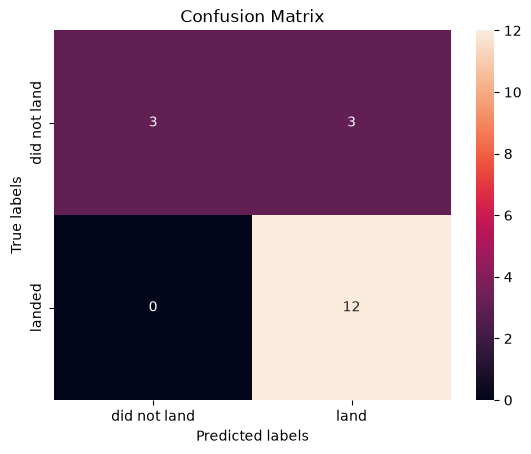

SVM Best Parameters: {'C': np.float64(1.0), 'gamma': np.float64(0.03162277660168379), 'kernel': 'sigmoid'}
SVM Validation Accuracy: 0.8482142857142856
SVM Test Accuracy: 0.8333333333333334


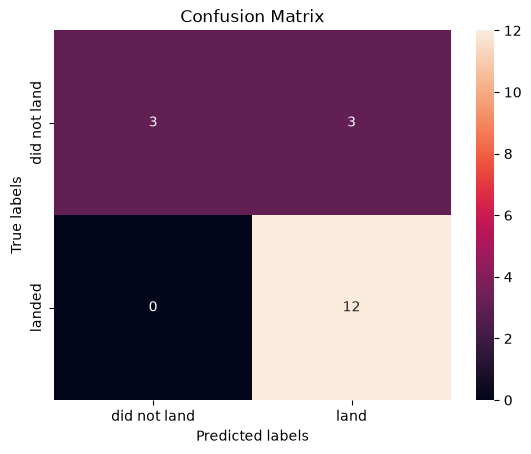

Decision Tree Best Parameters: {'criterion': 'entropy', 'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 5, 'splitter': 'random'}
Decision Tree Validation Accuracy: 0.8892857142857145
Decision Tree Test Accuracy: 0.8333333333333334


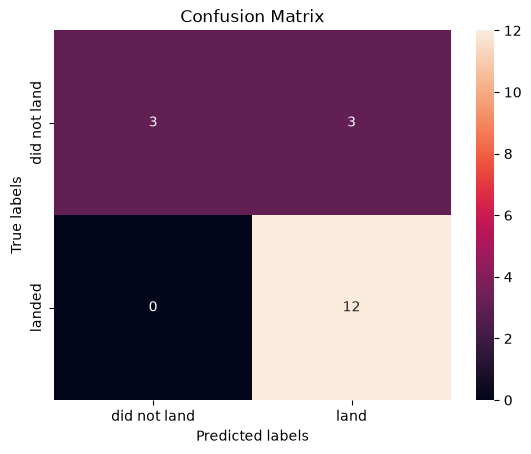

KNN Best Parameters: {'algorithm': 'auto', 'n_neighbors': 10, 'p': 1}
KNN Validation Accuracy: 0.8482142857142858
KNN Test Accuracy: 0.8333333333333334


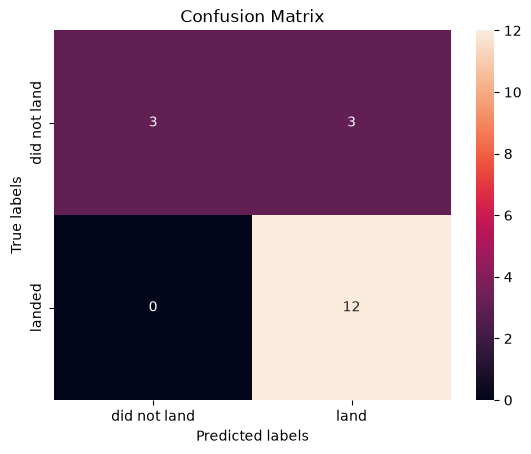


MODEL COMPARISON
                 Model  Test Accuracy
0  Logistic Regression       0.833333
1                  SVM       0.833333
2        Decision Tree       0.833333
3                  KNN       0.833333


/opt/anaconda3/lib/python3.14/site-packages/seaborn/_base.py:1447: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  self.plot_data[axis] = cat_data
/opt/anaconda3/lib/python3.14/site-packages/seaborn/categorical.py:1292: FutureWarning: ChainedA

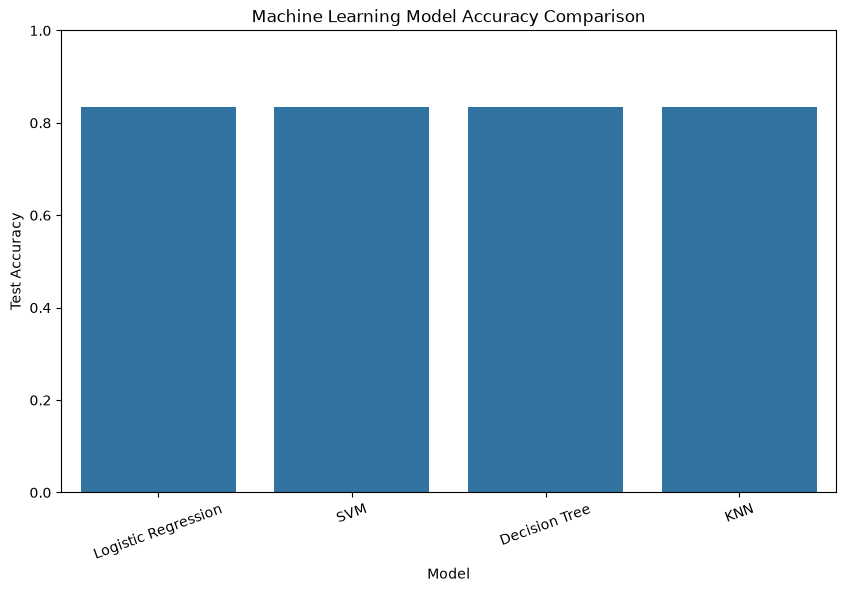

Best Model: Logistic Regression
Best Test Accuracy: 0.8333333333333334

IBM COURSE 10 — QUIZ ANSWERS
QUESTION 1: Number of test records
18

QUESTION 2: Best SVM kernel
sigmoid

QUESTION 3: Decision Tree test accuracy
83.33%


In [2]:

# ============================================================
# IBM DATA SCIENCE PROFESSIONAL CERTIFICATE — COURSE 10
# SPACEX MACHINE LEARNING PREDICTION — PART 5
# COMPLETE LAB: TASKS 1–12
# ============================================================

# INSTALL PACKAGES (uncomment if needed)
# %pip install numpy pandas matplotlib seaborn scikit-learn

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier


# ============================================================
# 2. CONFUSION MATRIX FUNCTION
# ============================================================

def plot_confusion_matrix(y, y_predict):
    "this function plots the confusion matrix"
    from sklearn.metrics import confusion_matrix

    cm = confusion_matrix(y, y_predict)
    ax = plt.subplot()
    sns.heatmap(cm, annot=True, ax=ax)
    ax.set_xlabel('Predicted labels')
    ax.set_ylabel('True labels')
    ax.set_title('Confusion Matrix')
    ax.xaxis.set_ticklabels(['did not land', 'land'])
    ax.yaxis.set_ticklabels(['did not land', 'landed'])
    plt.show()


# ============================================================
# 3. LOAD DATASETS
# ============================================================

data = pd.read_csv(
    "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv"
)

data.head()

X = pd.read_csv(
    "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_3.csv"
)

X.head(100)


# ============================================================
# TASK 1: CREATE TARGET VARIABLE Y
# ============================================================

Y = data['Class'].to_numpy()


# ============================================================
# TASK 2: STANDARDIZE FEATURES
# ============================================================

transform = preprocessing.StandardScaler()
X = transform.fit_transform(X)


# ============================================================
# TASK 3: SPLIT DATA INTO TRAINING AND TESTING
# ============================================================

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=2
)

print("Test dataset shape:", Y_test.shape)


# ============================================================
# TASK 4: LOGISTIC REGRESSION
# ============================================================

parameters = {
    'C': [0.01, 0.1, 1],
    'penalty': ['l2'],
    'solver': ['lbfgs']
}

lr = LogisticRegression()

logreg_cv = GridSearchCV(
    lr,
    parameters,
    cv=10
)

logreg_cv.fit(X_train, Y_train)

print("Logistic Regression Best Parameters:",
      logreg_cv.best_params_)

print("Logistic Regression Validation Accuracy:",
      logreg_cv.best_score_)


# ============================================================
# TASK 5: EVALUATE LOGISTIC REGRESSION
# ============================================================

logreg_accuracy = logreg_cv.score(X_test, Y_test)

print("Logistic Regression Test Accuracy:",
      logreg_accuracy)

yhat = logreg_cv.predict(X_test)

plot_confusion_matrix(Y_test, yhat)


# ============================================================
# TASK 6: SUPPORT VECTOR MACHINE (SVM)
# ============================================================

parameters = {
    'kernel': ('linear', 'rbf', 'poly', 'rbf', 'sigmoid'),
    'C': np.logspace(-3, 3, 5),
    'gamma': np.logspace(-3, 3, 5)
}

svm = SVC()

svm_cv = GridSearchCV(
    svm,
    parameters,
    cv=10
)

svm_cv.fit(X_train, Y_train)

print("SVM Best Parameters:",
      svm_cv.best_params_)

print("SVM Validation Accuracy:",
      svm_cv.best_score_)


# ============================================================
# TASK 7: EVALUATE SVM
# ============================================================

svm_accuracy = svm_cv.score(X_test, Y_test)

print("SVM Test Accuracy:", svm_accuracy)

yhat = svm_cv.predict(X_test)

plot_confusion_matrix(Y_test, yhat)


# ============================================================
# TASK 8: DECISION TREE CLASSIFIER
# ============================================================

parameters = {
    'criterion': ['gini', 'entropy'],
    'splitter': ['best', 'random'],
    'max_depth': [2*n for n in range(1, 10)],
    'max_features': [None, 'sqrt'],
    'min_samples_leaf': [1, 2, 4],
    'min_samples_split': [2, 5, 10]
}

tree = DecisionTreeClassifier()

tree_cv = GridSearchCV(
    tree,
    parameters,
    cv=10
)

tree_cv.fit(X_train, Y_train)

print("Decision Tree Best Parameters:",
      tree_cv.best_params_)

print("Decision Tree Validation Accuracy:",
      tree_cv.best_score_)


# ============================================================
# TASK 9: EVALUATE DECISION TREE
# ============================================================

tree_accuracy = tree_cv.score(X_test, Y_test)

print("Decision Tree Test Accuracy:",
      tree_accuracy)

yhat = tree_cv.predict(X_test)

plot_confusion_matrix(Y_test, yhat)


# ============================================================
# TASK 10: K-NEAREST NEIGHBORS (KNN)
# ============================================================

parameters = {
    'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
    'p': [1, 2]
}

KNN = KNeighborsClassifier()

knn_cv = GridSearchCV(
    KNN,
    parameters,
    cv=10
)

knn_cv.fit(X_train, Y_train)

print("KNN Best Parameters:",
      knn_cv.best_params_)

print("KNN Validation Accuracy:",
      knn_cv.best_score_)


# ============================================================
# TASK 11: EVALUATE KNN
# ============================================================

knn_accuracy = knn_cv.score(X_test, Y_test)

print("KNN Test Accuracy:",
      knn_accuracy)

yhat = knn_cv.predict(X_test)

plot_confusion_matrix(Y_test, yhat)


# ============================================================
# TASK 12: COMPARE ALL MODELS
# ============================================================

models = {
    "Logistic Regression": logreg_cv,
    "SVM": svm_cv,
    "Decision Tree": tree_cv,
    "KNN": knn_cv
}

results = {}

for name, model in models.items():
    results[name] = model.score(X_test, Y_test)

results_df = pd.DataFrame(
    list(results.items()),
    columns=["Model", "Test Accuracy"]
)

print("\nMODEL COMPARISON")
print(results_df)

# Plot accuracy comparison
plt.figure(figsize=(10, 6))
sns.barplot(
    data=results_df,
    x="Model",
    y="Test Accuracy"
)
plt.title("Machine Learning Model Accuracy Comparison")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.show()

best_model = max(results, key=results.get)

print("Best Model:", best_model)
print("Best Test Accuracy:", results[best_model])


# ============================================================
# FINAL QUIZ ANSWERS
# ============================================================

print("\n" + "=" * 45)
print("IBM COURSE 10 — QUIZ ANSWERS")
print("=" * 45)

print("QUESTION 1: Number of test records")
print(len(Y_test))

print("\nQUESTION 2: Best SVM kernel")
print(svm_cv.best_params_['kernel'])

print("\nQUESTION 3: Decision Tree test accuracy")
print(f"{tree_accuracy:.2%}")

print("=" * 45)


This function is to plot the confusion matrix.


In [ ]:
def plot_confusion_matrix(y,y_predict):
    "this function plots the confusion matrix"
    from sklearn.metrics import confusion_matrix

    cm = confusion_matrix(y, y_predict)
    ax= plt.subplot()
    sns.heatmap(cm, annot=True, ax = ax); #annot=True to annotate cells
    ax.set_xlabel('Predicted labels')
    ax.set_ylabel('True labels')
    ax.set_title('Confusion Matrix'); 
    ax.xaxis.set_ticklabels(['did not land', 'land']); ax.yaxis.set_ticklabels(['did not land', 'landed']) 
    plt.show() 

## Load the dataframe


Load the data


In [ ]:
data = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv")


In [ ]:
data.head()

In [ ]:

X = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_3.csv')

In [ ]:
X.head(100)

## TASK  1


Create a NumPy array from the column <code>Class</code> in <code>data</code>, by applying the method <code>to_numpy()</code>  then
assign it  to the variable <code>Y</code>,make sure the output is a  Pandas series (only one bracket df\['name of  column']).


## TASK  2


Standardize the data in <code>X</code> then reassign it to the variable  <code>X</code> using the transform provided below.


In [ ]:
# students get this 
transform = preprocessing.StandardScaler()

We split the data into training and testing data using the  function  <code>train_test_split</code>.   The training data is divided into validation data, a second set used for training  data; then the models are trained and hyperparameters are selected using the function <code>GridSearchCV</code>.


## TASK  3


Use the function train_test_split to split the data X and Y into training and test data. Set the parameter test_size to  0.2 and random_state to 2. The training data and test data should be assigned to the following labels.


<code>X_train, X_test, Y_train, Y_test</code>


we can see we only have 18 test samples.


In [ ]:
Y_test.shape

## TASK  4


Create a logistic regression object  then create a  GridSearchCV object  <code>logreg_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [ ]:
parameters ={'C':[0.01,0.1,1],
             'penalty':['l2'],
             'solver':['lbfgs']}

In [ ]:
parameters ={"C":[0.01,0.1,1],'penalty':['l2'], 'solver':['lbfgs']}# l1 lasso l2 ridge
lr=LogisticRegression()


We output the <code>GridSearchCV</code> object for logistic regression. We display the best parameters using the data attribute <code>best_params\_</code> and the accuracy on the validation data using the data attribute <code>best_score\_</code>.


In [ ]:
print("tuned hpyerparameters :(best parameters) ",logreg_cv.best_params_)
print("accuracy :",logreg_cv.best_score_)

## TASK  5


Calculate the accuracy on the test data using the method <code>score</code>:


Lets look at the confusion matrix:


In [ ]:
yhat=logreg_cv.predict(X_test)
plot_confusion_matrix(Y_test,yhat)

Examining the confusion matrix, we see that logistic regression can distinguish between the different classes.  We see that the problem is false positives.

Overview:

True Postive - 12 (True label is landed, Predicted label is also landed)

False Postive - 3 (True label is not landed, Predicted label is landed)


## TASK  6


Create a support vector machine object then  create a  <code>GridSearchCV</code> object  <code>svm_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [ ]:
parameters = {'kernel':('linear', 'rbf','poly','rbf', 'sigmoid'),
              'C': np.logspace(-3, 3, 5),
              'gamma':np.logspace(-3, 3, 5)}
svm = SVC()

In [ ]:
print("tuned hpyerparameters :(best parameters) ",svm_cv.best_params_)
print("accuracy :",svm_cv.best_score_)

## TASK  7


Calculate the accuracy on the test data using the method <code>score</code>:


We can plot the confusion matrix


In [ ]:
yhat=svm_cv.predict(X_test)
plot_confusion_matrix(Y_test,yhat)

## TASK  8


Create a decision tree classifier object then  create a  <code>GridSearchCV</code> object  <code>tree_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [ ]:
parameters = {'criterion': ['gini', 'entropy'],
     'splitter': ['best', 'random'],
     'max_depth': [2*n for n in range(1,10)],
     'max_features': ['auto', 'sqrt'],
     'min_samples_leaf': [1, 2, 4],
     'min_samples_split': [2, 5, 10]}

tree = DecisionTreeClassifier()

In [ ]:
print("tuned hpyerparameters :(best parameters) ",tree_cv.best_params_)
print("accuracy :",tree_cv.best_score_)

## TASK  9


Calculate the accuracy of tree_cv on the test data using the method <code>score</code>:


We can plot the confusion matrix


In [ ]:
yhat = tree_cv.predict(X_test)
plot_confusion_matrix(Y_test,yhat)

## TASK  10


Create a k nearest neighbors object then  create a  <code>GridSearchCV</code> object  <code>knn_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [ ]:
parameters = {'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
              'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
              'p': [1,2]}

KNN = KNeighborsClassifier()

In [ ]:
print("tuned hpyerparameters :(best parameters) ",knn_cv.best_params_)
print("accuracy :",knn_cv.best_score_)

## TASK  11


Calculate the accuracy of knn_cv on the test data using the method <code>score</code>:


We can plot the confusion matrix


In [ ]:
yhat = knn_cv.predict(X_test)
plot_confusion_matrix(Y_test,yhat)

## TASK  12


Find the method performs best:


## Authors


[Pratiksha Verma](https://www.linkedin.com/in/pratiksha-verma-6487561b1/)


<!--## Change Log--!>


<!--| Date (YYYY-MM-DD) | Version | Changed By      | Change Description      |
| ----------------- | ------- | -------------   | ----------------------- |
| 2022-11-09        | 1.0     | Pratiksha Verma | Converted initial version to Jupyterlite|--!>


### <h3 align="center"> IBM Corporation 2022. All rights reserved. <h3/>
